# Setup

In [1]:
from pprint import pprint
from tempfile import TemporaryDirectory
from pathlib import Path


# Seed
seed = 42


# Workspace
workspace = TemporaryDirectory(     # temporary create a folder.
    prefix='ai_summary_prac_',
)
source_path = Path(workspace.name) / 'average.py'

print(f"Target source path: {source_path}")

Target source path: C:\Users\yana\AppData\Local\Temp\ai_summary_prac_97a08cnd\average.py


# 1. ReAct

In [2]:
import json
from langchain_ollama import ChatOllama
from langchain.tools import tool
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain_core.messages import ToolMessage
from typing_extensions import TypedDict, List
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from IPython.display import Image
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage


src_init = """
def average(values: List[float]) -> float:
    '''Calculates the mean of floats.'''
"""

test_cases = [
    [],
    [0],
    [0, 0],
    [1, 2],
    [1, 1, 1],
]

test_answers = [
    0.0,
    0,
    0,
    1.5,
    1,
]

namespace = {}      # for exec(src, namespace).

Test results:
[True, True, True, True, True]
Final source:
def average(values: List[float]) -> float:
    '''Calculates the mean of floats.'''
    if len(values) == 0:
        return 0.0
    return sum(values) / len(values)


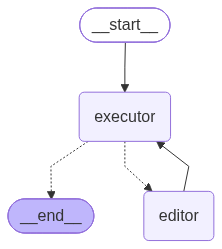

('Final state:\n'
 '{\'src\': "def average(values: List[float]) -> float:\\n    \'\'\'Calculates '
 "the mean of floats.'''\\n    if len(values) == 0:\\n        return 0.0\\n    "
 'return sum(values) / len(values)", \'test_cases\': [[], [0], [0, 0], [1, 2], '
 "[1, 1, 1]], 'test_answers': [0.0, 0, 0, 1.5, 1], 'test_results': [True, "
 'True, True, True, True]}')

State history (last -> first):
{'src': 'def average(values: List[float]) -> float:\n'
        "    '''Calculates the mean of floats.'''\n"
        '    if len(values) == 0:\n'
        '        return 0.0\n'
        '    return sum(values) / len(values)',
 'test_answers': [0.0, 0, 0, 1.5, 1],
 'test_cases': [[], [0], [0, 0], [1, 2], [1, 1, 1]],
 'test_results': [True, True, True, True, True]}
{'src': 'def average(values: List[float]) -> float:\n'
        "    '''Calculates the mean of floats.'''\n"
        '    if len(values) == 0:\n'
        '        return 0.0\n'
        '    return sum(values) / len(values)',
 'test_answers

In [3]:
from math import isclose


# Chat
chat = ChatOllama(
    model='qwen3:4b',
    temperature=1.0,
    top_k=10,
    top_p=0.9,
    reasoning=True,
    seed=seed,
)


# State
class State(TypedDict):
    src: str
    test_cases: List[List[float]]
    test_answers: List[float]
    test_results: List[bool]


# Tool
@tool
def run_src(
    src: str,
    test_cases: List[List[float]],
    test_answers: List[float],
) -> List[bool]:
    """Run the source code on test cases and return results."""

    if len(test_cases) != len(test_answers):
        raise ValueError("Each test case needs an expected answer.")

    results = []
    for i in range(len(test_cases)):
        try:
            namespace = {'List': List}
            exec(src, namespace)
            result = namespace['average'](test_cases[i].copy())

            if type(result) in (int, float) and isclose(
                result, test_answers[i], rel_tol=1e-9, abs_tol=1e-12
            ):
                results.append(True)
            else:
                results.append(False)

        except Exception:
            results.append(False)       # error -> fail.

    return results


@tool
def write_src(src: str) -> str:
    """Write the complete Python source code to average.py."""
    source_path.write_text(src, encoding='utf-8')
    
    return 'Source code written to average.py.'


# Agent
run_limit = 2
middleware = [
    ModelCallLimitMiddleware(
        run_limit=run_limit,
        exit_behavior='end',
    )
]

executor = create_agent(
    model=chat,
    tools=[run_src],
    system_prompt=(
        "The user provides the current state as JSON. "
        "Call run_src once with exactly the supplied src, test_cases, "
        "and test_answers. "
        "Keep all three arguments unchanged. "
        "After the tool returns, finish."
    ),
    middleware=middleware,
)

editor = create_agent(
    model=chat,
    tools=[write_src],
    system_prompt=(
        "The user provides the current state as JSON. "
        "Read src, test_cases, test_answers, and test_results. "
        "Repair average(values) in average.py. Keep the function name and argument. "
        "For an empty list, return 0.0. Otherwise return the arithmetic mean. "
        "Handle fractional results, negative numbers, and decimal inputs correctly. "
        "Call write_src once with the complete repaired Python source, then finish."
    ),
    middleware=middleware,
)


# Nodes: connect the graph state to each agent.
def executor_node(state: State):
    response = executor.invoke({
        'messages': [HumanMessage(json.dumps(state))]
    })

    # Read the actual tool output.
    for message in reversed(response['messages']):
        if (
            isinstance(message, ToolMessage)
            and message.name == 'run_src'
            and message.status == 'success'
        ):
            return {'test_results': json.loads(message.content)}

    raise RuntimeError('The executor did not successfully call run_src.')


def editor_node(state: State):
    response = editor.invoke({
        'messages': [
            {'role': 'user', 'content': json.dumps(state)},
        ],
    })

    for message in reversed(response['messages']):
        if (
            isinstance(message, ToolMessage)
            and message.name == 'write_src'
            and message.status == 'success'
        ):
            # Synchronize the graph state with the file the editor wrote.
            return {'src': source_path.read_text(encoding='utf-8'), 'test_results': []}

    raise RuntimeError('The editor did not successfully call write_src.')


# Conditional edges
def is_passed(state: State) -> str:
    """Return the next node based on the test results."""
    if (
        len(state['test_results']) == len(state['test_cases']) > 0
        and all(state['test_results'])
    ):
        return END
    else:
        return 'editor'


# Graph
builder = StateGraph(State)

builder.add_node('executor', executor_node)
builder.add_node('editor', editor_node)

builder.add_edge(START, 'executor')
builder.add_conditional_edges('executor', is_passed, [END, 'editor'])
builder.add_edge('editor', 'executor')

graph = builder.compile(
    checkpointer=InMemorySaver(),
)


# Run
config = {
    'configurable': {'thread_id': 'prac'},
    'recursion_limit': 20,
}
results = graph.invoke(
    input={
        'src': src_init,
        'test_cases': test_cases,
        'test_answers': test_answers,
        'test_results': [],
    },
    config=config,
)

print(f"Test results:\n{results['test_results']}")
print(f"Final source:\n{results['src']}")


# Visualize
Path('diagrams').mkdir(parents=True, exist_ok=True)
image_bytes = graph.get_graph().draw_mermaid_png(
    output_file_path='diagrams/react.png',
)
image = Image(image_bytes)

display(image)


# State history
pprint(f"Final state:\n{graph.get_state(config).values}")

print("\nState history (last -> first):")
for history in graph.get_state_history(config):
    pprint(history.values)

# 2. Plan-and-Execute

- Planner: task -> many executable subtasks
- Executor: execute one subtask
- Controller: record the result of execution, and decide the next subtask to execute

succeeded
[True, True, True, True, True]
def average(values: List[float]) -> float:
    if len(values) == 0:
        return 0.0
    return sum(values) / len(values)


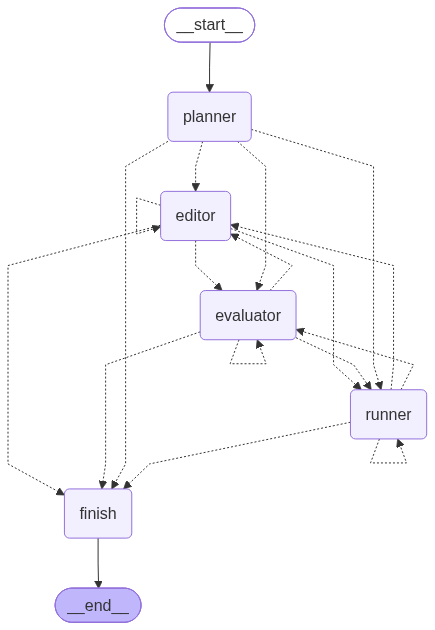

In [4]:
from langchain_ollama import ChatOllama
from typing_extensions import TypedDict, List, Literal
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from pydantic import BaseModel, Field
from langchain.tools import tool
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain.agents.middleware import ModelCallLimitMiddleware
from math import isclose
from IPython.display import Image


# Constants
MODEL_CALL_LIMIT = 5


# 1. Chat
chat = ChatOllama(
    model='qwen3:4b',
    top_k=10,
    top_p=0.9,
    reasoning=True,
    seed=seed,
)


# 2. State
class State(TypedDict):
    code: str
    test_cases: List[List[float]]   # test inputs.
    test_outputs: List[float | None]  # code execution outputs.
    test_errors: List[str | None]
    test_answers: List[float]       # correct answers.
    test_results: List[bool]        # True if correct.
    plan: List[dict[str, str]]
    step_index: int
    status: str
    error: str


# 3. Tool & Agent
def planner(state: State) -> dict:
    """Generate the plan for code-fixing task."""
    result = planner_agent.invoke(
        input={
            'messages': [HumanMessage(content=(
                f"Code:\n{state['code']}\n"
                f"Test inputs: {state['test_cases']}\n"
                f"Expected outputs: {state['test_answers']}\n"
                "Use runner before evaluator. "
                "After editing, run and evaluate again."
            ))],
        },
        config={'recursion_limit': 40},
    )
    plan = result.get('structured_response')
    if plan is None:
        return {'status': 'blocked', 'error': 'Planner did not return a valid Plan within its call limit.'}

    return {'plan': plan.model_dump()['steps'], 'step_index': 0}

class Subtask(BaseModel):
    worker: Literal['runner', 'evaluator', 'editor']
    task: str

class Plan(BaseModel):
    steps: List[Subtask] = Field(min_length=1, max_length=8)

planner_agent = create_agent(
    model=chat,
    tools=[],
    system_prompt=(
        "You are a planner for code fix system. "
        "You have 3 workers: runner, evaluator, editor. "
        "Generate an ordered plan to repair average(values) in average.py. "
        "Keep the function name and argument. "
        "For an empty list, return 0.0. Otherwise return the arithmetic mean. "
        "Handle fractional results, negative numbers, and decimal inputs correctly. "
        "Submit the plan using the Plan tool."
    ),
    response_format=ToolStrategy(Plan),
    middleware=[ModelCallLimitMiddleware(run_limit=MODEL_CALL_LIMIT, exit_behavior="end")],
)


def runner(state: State) -> dict:
    """Run the code and return test outputs and errors."""
    outputs, errors = [], []
    for values in state['test_cases']:
        try:
            namespace = {'List': List}
            exec(state['code'], namespace)
            output = namespace['average'](values.copy())
            if type(output) not in (int, float):
                raise TypeError("Expected a numeric result.")
            outputs.append(output)
            errors.append(None)
        except Exception as error:
            outputs.append(None)
            errors.append(f"{type(error).__name__}: {error}")

    return {
        'test_outputs': outputs,
        'test_errors': errors,
        'test_results': [],
        'step_index': state['step_index'] + 1,
    }


def evaluator(state: State) -> dict:
    """Compare the actual outputs with the expected answers."""
    outputs, answers = state['test_outputs'], state['test_answers']
    if len(outputs) != len(answers):
        raise ValueError("Run all tests before evaluation.")

    results = [
        output is not None
        and isclose(output, answer, rel_tol=1e-9, abs_tol=1e-12)
        for output, answer in zip(outputs, answers)
    ]
    return {'test_results': results, 'step_index': state['step_index'] + 1}


class EditedCode(BaseModel):
    code: str = Field(description="Complete Python source, without Markdown fences.")


editor_agent = create_agent(
    model=chat,
    tools=[],
    system_prompt=(
        "You are a code-fixing editor. "
        "Write or repair average(values) in average.py. "
        "Keep the function name and argument. "
        "For an empty list, return 0.0. Otherwise return the arithmetic mean. "
        "Handle fractional results, negative numbers, and decimal inputs correctly. "
        "Submit the complete source using the EditedCode tool."
    ),
    response_format=ToolStrategy(EditedCode),
    middleware=[ModelCallLimitMiddleware(run_limit=MODEL_CALL_LIMIT, exit_behavior="end")],
)

def editor(state: State) -> dict:
    """Edit the code and update the current source."""
    code_old = state['code']
    task = state['plan'][state['step_index']]['task']
    result = editor_agent.invoke(
        input={
            'messages': [HumanMessage(content=(
                f"Task: {task}\n"
                f"Code:\n{code_old}\n"
                f"Test inputs: {state['test_cases']}\n"
                f"Expected: {state['test_answers']}\n"
                f"Actual: {state['test_outputs']}\n"
                f"Errors: {state['test_errors']}\n"
                f"Results: {state['test_results']}"
            ))],
        },
        config={'recursion_limit': 40},
    )
    edited = result.get('structured_response')
    if edited is None:
        return {'status': 'blocked', 'error': 'Editor did not return valid EditedCode within its call limit.'}
    code_edited = edited.code
    source_path.write_text(code_edited, encoding='utf-8')

    return {
        'code': code_edited,
        'test_outputs': [],
        'test_errors': [],
        'test_results': [],
        'step_index': state['step_index'] + 1,
    }


def all_passed(state: State) -> bool:
    results = state['test_results']
    return len(results) == len(state['test_cases']) > 0 and all(results)


def controller(state: State):
    if state['status'] == 'blocked' or all_passed(state):
        return 'finish'
    if state['step_index'] >= len(state['plan']):
        return 'finish'

    worker = state['plan'][state['step_index']]['worker']
    if worker == 'evaluator' and not (
        len(state['test_outputs']) == len(state['test_answers'])
        == len(state['test_cases']) > 0
    ):
        return 'finish'
    return worker


def finish(state: State) -> dict:
    if state['status'] == 'blocked':
        return {'status': 'blocked'}
    return {'status': 'succeeded' if all_passed(state) else 'failed'}


# 4. Graph
builder = StateGraph(State)

for name, node in [
    ('planner', planner),
    ('runner', runner),
    ('evaluator', evaluator),
    ('editor', editor),
]:
    builder.add_node(name, node)
    builder.add_conditional_edges(
        name, controller, ['runner', 'evaluator', 'editor', 'finish'],
    )
builder.add_node('finish', finish)
builder.add_edge(START, 'planner')
builder.add_edge('finish', END)

graph = builder.compile()


# 5. Run
initial_state: State = {
    'code': src_init,
    'test_cases': test_cases,
    'test_answers': test_answers,
    'test_outputs': [],
    'test_errors': [],
    'test_results': [],
    'plan': [],
    'step_index': 0,
    'status': 'running',
    'error': '',
}
response = graph.invoke(initial_state, config={'recursion_limit': 40})

print(response['status'])
print(response['test_results'])
print(response['code'])
if response['error']:
    print('Error:', response['error'])

graph_image = Image(
    graph.get_graph().draw_mermaid_png()
)
display(graph_image)

# 3. Replanning

In [5]:
# Run this cell independently; it does not depend on earlier notebook cells.
from copy import deepcopy
from math import isclose
from pathlib import Path
from tempfile import TemporaryDirectory
from typing_extensions import TypedDict, List, Literal

from langchain_ollama import ChatOllama
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.agents.structured_output import ToolStrategy
from langchain.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field


# Constants
seed = 42
MAX_REPLANS = 2
MODEL_CALL_LIMIT = 5
replan_workspace = TemporaryDirectory(prefix='ai_summary_replan_')
source_path = Path(replan_workspace.name) / 'average.py'


# 1. Chat
chat = ChatOllama(
    model='qwen3:4b',
    top_k=10,
    top_p=0.9,
    reasoning=True,
    seed=seed,
)


# 2. State and response schemas
class ReplanState(TypedDict):
    code: str
    test_cases: List[List[float]]
    test_outputs: List[float | None]
    test_errors: List[str | None]
    test_answers: List[float]
    test_results: List[bool]
    plan: List[dict[str, str]]
    step_index: int
    status: str
    error: str
    replan_count: int


class Subtask(BaseModel):
    worker: Literal['runner', 'evaluator', 'editor']
    task: str


class Plan(BaseModel):
    steps: List[Subtask] = Field(min_length=1, max_length=8)


class EditedCode(BaseModel):
    code: str = Field(description='Complete Python source, without Markdown fences.')


# 3. Agents and nodes
planner_agent = create_agent(
    model=chat,
    tools=[],
    system_prompt=(
        'You are a planner for a code-fixing system. '
        'You have 3 workers: runner, evaluator, editor. '
        'Generate an ordered plan to repair average(values) in average.py. '
        'Keep the function name and argument. '
        'For an empty list, return 0.0. Otherwise return the arithmetic mean. '
        'Handle fractional results, negative numbers, and decimal inputs correctly. '
        'Submit the plan using the Plan tool.'
    ),
    response_format=ToolStrategy(Plan),
    middleware=[ModelCallLimitMiddleware(run_limit=MODEL_CALL_LIMIT, exit_behavior='end')],
)

editor_agent = create_agent(
    model=chat,
    tools=[],
    system_prompt=(
        'You are a code-fixing editor. '
        'Repair average(values) without changing its name or argument. '
        'Return 0.0 for an empty list; otherwise return its arithmetic mean. '
        'Handle fractional, negative, and decimal values. '
        'Return complete Python source without Markdown fences. '
        'Submit the complete source using the EditedCode tool.'
    ),
    response_format=ToolStrategy(EditedCode),
    middleware=[ModelCallLimitMiddleware(run_limit=MODEL_CALL_LIMIT, exit_behavior='end')],
)


# These are graph nodes, not @tool functions: return state-update dictionaries.
def planner(state: ReplanState) -> dict:
    result = planner_agent.invoke(
        {'messages': [HumanMessage(content=(
            f"Code:\n{state['code']}\n"
            f"Test inputs: {state['test_cases']}\n"
            f"Expected outputs: {state['test_answers']}\n"
            'Use runner before evaluator. '
            'After editing, run and evaluate again.'
        ))]},
        config={'recursion_limit': 40},
    )
    plan = result.get('structured_response')
    if plan is None:
        return {'status': 'blocked', 'error': 'Planner did not return a valid Plan within its call limit.'}

    return {'plan': plan.model_dump()['steps'], 'step_index': 0}


def runner(state: ReplanState) -> dict:
    outputs, errors = [], []

    # Learning-only: exec() is not a security sandbox and has no timeout.
    for values in state['test_cases']:
        try:
            namespace = {'List': List}
            exec(state['code'], namespace)
            output = namespace['average'](values.copy())
            if type(output) not in (int, float):
                raise TypeError('Expected a numeric result.')
            outputs.append(output)
            errors.append(None)
        except Exception as error:
            outputs.append(None)
            errors.append(f'{type(error).__name__}: {error}')

    return {
        'test_outputs': outputs,
        'test_errors': errors,
        'test_results': [],
        'step_index': state['step_index'] + 1,
    }


def evaluator(state: ReplanState) -> dict:
    outputs, answers = state['test_outputs'], state['test_answers']
    if len(outputs) != len(answers):
        raise ValueError('Run all tests before evaluation.')

    results = [
        output is not None
        and isclose(output, answer, rel_tol=1e-9, abs_tol=1e-12)
        for output, answer in zip(outputs, answers)
    ]
    return {'test_results': results, 'step_index': state['step_index'] + 1}


def editor(state: ReplanState) -> dict:
    task = state['plan'][state['step_index']]['task']
    result = editor_agent.invoke(
        {'messages': [HumanMessage(content=(
            f"Task: {task}\n"
            f"Code:\n{state['code']}\n"
            f"Test inputs: {state['test_cases']}\n"
            f"Expected: {state['test_answers']}\n"
            f"Actual: {state['test_outputs']}\n"
            f"Errors: {state['test_errors']}\n"
            f"Results: {state['test_results']}"
        ))]},
        config={'recursion_limit': 40},
    )
    edited = result.get('structured_response')
    if edited is None:
        return {'status': 'blocked', 'error': 'Editor did not return valid EditedCode within its call limit.'}
    code_edited = edited.code

    source_path.write_text(code_edited, encoding='utf-8')
    return {
        'code': code_edited,
        'test_outputs': [],
        'test_errors': [],
        'test_results': [],
        'step_index': state['step_index'] + 1,
    }


def all_passed(state: ReplanState) -> bool:
    results = state['test_results']
    return len(results) == len(state['test_cases']) > 0 and all(results)


def finish(state: ReplanState) -> dict:
    if state['status'] == 'blocked':
        return {'status': 'blocked'}
    return {'status': 'succeeded' if all_passed(state) else 'failed'}


# Reuse the planner with execution feedback.
def replan(state: ReplanState) -> dict:
    completed = state['plan'][:state['step_index']]

    result = planner_agent.invoke(
        {'messages': [HumanMessage(content=(
            f"Current code:\n{state['code']}\n"
            f"Test inputs: {state['test_cases']}\n"
            f"Expected: {state['test_answers']}\n"
            f"Actual: {state['test_outputs']}\n"
            f"Errors: {state['test_errors']}\n"
            f"Results: {state['test_results']}\n"
            f"Previous plan: {state['plan']}\n"
            f"Completed steps in that plan: {completed}\n"
            'The task is not verified as successful. '
            'Generate only the remaining work using this evidence. '
            'Use runner before evaluator. '
            'After every edit, run and evaluate again.'
        ))]},
        config={'recursion_limit': 40},
    )
    plan = result.get('structured_response')
    if plan is None:
        return {'status': 'blocked', 'error': 'Planner did not return a valid Plan within its call limit.'}

    return {
        'plan': plan.model_dump()['steps'],
        'step_index': 0,
        'replan_count': state['replan_count'] + 1,
    }


def controller_replanning(state: ReplanState):
    if state['status'] == 'blocked' or all_passed(state):
        return 'finish'

    if state['step_index'] < len(state['plan']):
        worker = state['plan'][state['step_index']]['worker']
        ready = (
            len(state['test_outputs'])
            == len(state['test_answers'])
            == len(state['test_cases']) > 0
        )

        # Do not evaluate before test outputs exist.
        if worker != 'evaluator' or ready:
            return worker

    # Replan if the plan is exhausted or evaluation cannot run yet.
    return 'replan' if state['replan_count'] < MAX_REPLANS else 'finish'


# 4. Graph
builder = StateGraph(ReplanState)

for name, node in [
    ('planner', planner),
    ('runner', runner),
    ('evaluator', evaluator),
    ('editor', editor),
    ('replan', replan),
]:
    builder.add_node(name, node)
    builder.add_conditional_edges(
        name,
        controller_replanning,
        ['runner', 'evaluator', 'editor', 'replan', 'finish'],
    )

builder.add_node('finish', finish)
builder.add_edge(START, 'planner')
builder.add_edge('finish', END)

replanning_graph = builder.compile()


# 5. Start a fresh run; do not reuse the previous final response.
initial_state: ReplanState = {
    'code': 'def average(values):\n    return sum(values) // len(values)\n',
    'test_cases': [[], [0], [1, 2], [-2, -3], [0.1, 0.2, 0.3]],
    'test_answers': [0.0, 0.0, 1.5, -2.5, 0.2],
    'test_outputs': [],
    'test_errors': [],
    'test_results': [],
    'plan': [],
    'step_index': 0,
    'status': 'running',
    'error': '',
    'replan_count': 0,
}

response = replanning_graph.invoke(
    deepcopy(initial_state),
    config={'recursion_limit': 40},
)

print('Status:', response['status'])
print('Replans:', response['replan_count'])
print('Results:', response['test_results'])
print(response['code'])

if response['error']:
    print('Error:', response['error'])

Status: succeeded
Replans: 0
Results: [True, True, True, True, True]
def average(values):
    if not values:
        return 0.0
    return sum(values) / len(values)
